# Hardware-Executable Quasi-Inverse via Stinespring Dilation — Eight-Channel Version

The channel is implemented as a system–environment unitary, not an Aer noise instruction:

$$\mathcal E(\rho)=\operatorname{Tr}_E\!\left[U_{SE}(\rho\otimes|0\rangle\langle0|_E)U_{SE}^\dagger\right].$$

The quasi-inverse $V$ is found **numerically from the MSTD Bloch-ball integration**, then appended as a one-qubit `UnitaryGate`. Mixed inputs are prepared by purification. Set `EXECUTION_MODE` to `"simulator"` or `"qpu"`.

## 1. Imports

Numerical tools, Qiskit circuit classes, Aer for local checks, and IBM Runtime for QPU execution.

In [ ]:
import sys
!{sys.executable} -m pip install qiskit==2.4 qiskit-aer qiskit-ibm-runtime==0.46
! pip install matplotlib

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="IBM_TOKEN_HERE",
    set_as_default=True,
    overwrite= True
)

print("Account saved successfully!")

Account saved successfully!


In [ ]:
import json
import math
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import numpy as np

import matplotlib.pyplot as plt

from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import UnitaryGate
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Local, credential-free simulator backend (default execution path).
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler

## 2. Configuration

Choose the channel, input Bloch state $\rho=(I+r\hat n\cdot\sigma)/2$, execution mode, shots, and numerical grid used to find $V$.

In [ ]:
# ============================================================
# ============================================================

# -------------------------
# CHANNEL SELECTION
# -------------------------

# Single-qubit channels
CHANNEL_TYPE = "bit_flip"
CHANNEL_PARAMS = {"p": 0.55}

# Other single-qubit channels:
# CHANNEL_TYPE = "amplitude_damping"
# CHANNEL_PARAMS = {"gamma": 0.35}

# CHANNEL_TYPE = "phase_damping"
# CHANNEL_PARAMS = {"lam": 0.40}

# CHANNEL_TYPE = "phase_flip"
# CHANNEL_PARAMS = {"p": 0.70}


# -------------------------
# PAULI CHANNEL
# -------------------------
# P1: Identity
#CHANNEL_TYPE = "pauli"
#CHANNEL_PARAMS = {"p0": 1.0, "p1": 0.0, "p2": 0.0, "p3": 0.0}

# P2: Pure X / Bit Flip
#CHANNEL_TYPE = "pauli"
#CHANNEL_PARAMS = {"p0": 0.0, "p1": 1.0, "p2": 0.0, "p3": 0.0}

# P3: Pure Y
# CHANNEL_TYPE = "pauli"
# CHANNEL_PARAMS = {"p0": 0.0, "p1": 0.0, "p2": 1.0, "p3": 0.0}

# P4: Pure Z / Phase Flip
# CHANNEL_TYPE = "pauli"
# CHANNEL_PARAMS = {"p0": 0.0, "p1": 0.0, "p2": 0.0, "p3": 1.0}

# P5: Symmetric depolarizing
#CHANNEL_TYPE = "pauli"
#CHANNEL_PARAMS = {"p0": 0.25, "p1": 0.25, "p2": 0.25, "p3": 0.25}

# P6: Appendix / notebook point
# CHANNEL_TYPE = "pauli"
# CHANNEL_PARAMS = {"p0": 0.1, "p1": 0.5, "p2": 0.2, "p3": 0.2}

# P7: Weak Pauli
# CHANNEL_TYPE = "pauli"
# CHANNEL_PARAMS = {"p0": 0.1, "p1": 0.1, "p2": 0.7, "p3": 0.1}


# -------------------------
# GENERALIZED AMPLITUDE DAMPING
# -------------------------
#CHANNEL_TYPE = "GAD"
#CHANNEL_PARAMS = {"gamma": 0.0, "p": 1}
# G1
# CHANNEL_TYPE = "GAD"
# CHANNEL_PARAMS = {"gamma": 1.0, "p": 0.5}

# G2
# CHANNEL_TYPE = "GAD"
# CHANNEL_PARAMS = {"gamma": 0.9, "p": 0.5}

# G3
# CHANNEL_TYPE = "GAD"
# CHANNEL_PARAMS = {"gamma": 0.7, "p": 0.5}

# G4
# CHANNEL_TYPE = "GAD"
# CHANNEL_PARAMS = {"gamma": 0.5, "p": 0.2}

# G5
# CHANNEL_TYPE = "GAD"
# CHANNEL_PARAMS = {"gamma": 0.0, "p": 0.7}

# G6
#CHANNEL_TYPE = "GAD"
#CHANNEL_PARAMS = {"gamma": -0.5, "p": 0.7}


# -------------------------
# MIXED-UNITARY CHANNEL
# -------------------------

# M1
# CHANNEL_TYPE = "mixed_unitary"
# CHANNEL_PARAMS = {"p": 0.0, "theta": 0.0}

# M2
# CHANNEL_TYPE = "mixed_unitary"
# CHANNEL_PARAMS = {"p": 0.1, "theta": np.pi}

# M3
# CHANNEL_TYPE = "mixed_unitary"
# CHANNEL_PARAMS = {"p": 1/3, "theta": np.pi}

# M4
# CHANNEL_TYPE = "mixed_unitary"
# CHANNEL_PARAMS = {"p": 0.2, "theta": np.pi/2}

# M5
#CHANNEL_TYPE = "mixed_unitary"
#CHANNEL_PARAMS = {"p": 0.18, "theta": np.pi/3}


# -------------------------
# TETRAHEDRON CHANNEL
# -------------------------

# T1
# CHANNEL_TYPE = "tetrahedron"
# CHANNEL_PARAMS = {"p": 0.0, "pp": 0.0}

# T2
# CHANNEL_TYPE = "tetrahedron"
# CHANNEL_PARAMS = {"p": 0.25, "pp": 0.0}

# T3
# CHANNEL_TYPE = "tetrahedron"
# CHANNEL_PARAMS = {"p": 0.0, "pp": 0.25}

# T4
# CHANNEL_TYPE = "tetrahedron"
# CHANNEL_PARAMS = {"p": 0.1, "pp": 0.1}

# T5
# CHANNEL_TYPE = "tetrahedron"
# CHANNEL_PARAMS = {"p": 0.2, "pp": 0.1}

# T6
#CHANNEL_TYPE = "tetrahedron"
#CHANNEL_PARAMS = {"p": 0.25, "pp": 0.25}


# ============================================================
# INPUT STATE — TEST MATRIX
# ============================================================

# S1 — Maximally mixed
#R_IN = 0.0
#THETA_IN = 0.0
#PHI_IN = 0.0

# S2
# R_IN = 0.25
# THETA_IN = 0.0
# PHI_IN = 0.0

# S3
# R_IN = 0.50
# THETA_IN = 0.0
# PHI_IN = 0.0

# S4 — CURRENT BASELINE
#R_IN = 0.70
#THETA_IN = np.pi / 3
#PHI_IN = np.pi / 4

# S5 — Pure +Z
#R_IN = 1.0
#THETA_IN = 0.0
#PHI_IN = 0.0

# S6 — Pure +X
#R_IN = 1.0
#THETA_IN = np.pi / 2
#PHI_IN = 0.0

# S7 — Pure +Y
# R_IN = 1.0
# THETA_IN = np.pi / 2
# PHI_IN = np.pi / 2

# S8 — Pure -Z
# R_IN = 1.0
#THETA_IN = np.pi
#PHI_IN = 0.0

# S9
# R_IN = 0.50
# THETA_IN = np.pi / 2
# PHI_IN = np.pi / 4

# S10
R_IN = 0.50
THETA_IN = 2 * np.pi / 3
PHI_IN = 5 * np.pi / 4


# ============================================================
# EXECUTION / HARDWARE SETTINGS
# ============================================================

SHOTS = 2048

# "simulator" or "qpu"
EXECUTION_MODE = "qpu"

BACKEND_NAME = "ibm_fez"

OPTIMIZATION_LEVEL = 0
SEED_TRANSPILER = 12345
SIMULATOR_SEED = 2026


# ============================================================
# QUASI-INVERSE NUMERICAL INTEGRATION
# ============================================================

# 40 = thesis/reference workflow
V_INTEGRATION_GRID = 40


# ============================================================
# MSTD CAMPAIGN
# ============================================================

# False = single-state test
# True  = run MSTD campaign
RUN_MSTD_CAMPAIGN = True

# Matrix baseline uses 12 states for the current smoke-test campaign.
N_MSTD_STATES = 12

RNG_SEED = 2026


# ============================================================
# RESULTS
# ============================================================

RESULTS_JSON = Path("stinespring_qpu_results.json")

## 3. Channel Definitions


In [ ]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
SIGMA = [X, Y, Z]


def apply_channel_kraus(rho: np.ndarray, kraus_ops: Sequence[np.ndarray]) -> np.ndarray:
    # Initialize sum with a zero array of the same shape as rho to ensure return type is always ndarray.
    return sum((K @ rho @ K.conj().T for K in kraus_ops), start=np.zeros_like(rho))


def get_kraus_operators(channel_type: str, params: Dict) -> List[np.ndarray]:
    if channel_type == "pauli":
        probs = np.array([params["p0"], params["p1"], params["p2"], params["p3"]], dtype=float)
        if np.any(probs < -1e-12) or not np.isclose(probs.sum(), 1.0, atol=1e-10):
            raise ValueError("Pauli probabilities must be non-negative and sum to 1.")
        return [
            np.sqrt(probs[0]) * I2,
            np.sqrt(probs[1]) * X,
            np.sqrt(probs[2]) * Y,
            np.sqrt(probs[3]) * Z,
        ]

    if channel_type == "GAD":
        gamma = float(params["gamma"])
        p = float(params["p"])
        if not (-1.0 <= gamma <= 1.0):
            raise ValueError("For the paper's GAD parametrization, gamma must lie in [-1, 1].")
        if not (0.0 <= p <= 1.0):
            raise ValueError("GAD p must lie in [0, 1].")
        s = np.sqrt(max(0.0, 1.0 - gamma**2))
        return [
            np.sqrt(p) * np.array([[1, 0], [0, gamma]], dtype=complex),
            np.sqrt(p) * np.array([[0, s], [0, 0]], dtype=complex),
            np.sqrt(1 - p) * np.array([[gamma, 0], [0, 1]], dtype=complex),
            np.sqrt(1 - p) * np.array([[0, 0], [s, 0]], dtype=complex),
        ]

    if channel_type == "mixed_unitary":
        p = float(params["p"])
        theta = float(params["theta"])
        if not (0.0 <= p <= 1.0 / 3.0):
            raise ValueError("mixed_unitary requires 0 <= p <= 1/3.")
        kraus = [np.sqrt(1 - 3 * p) * I2]
        for sigma in SIGMA:
            Ui = np.cos(theta / 2) * I2 - 1j * np.sin(theta / 2) * sigma
            kraus.append(np.sqrt(p) * Ui)
        return kraus

    if channel_type == "tetrahedron":
        p = float(params["p"])
        pp = float(params["pp"])
        if p < 0 or pp < 0 or p + pp > 0.5 + 1e-12:
            raise ValueError("tetrahedron requires p>=0, p'>=0, p+p'<=1/2.")
        v = [
            np.array([1, 1, 1], dtype=float) / np.sqrt(3),
            np.array([1, -1, -1], dtype=float) / np.sqrt(3),
            np.array([-1, 1, -1], dtype=float) / np.sqrt(3),
            np.array([-1, -1, 1], dtype=float) / np.sqrt(3),
        ]
        probs = [pp, p, p, pp]
        q = 1.0 - 2.0 * p - 2.0 * pp
        kraus = [np.sqrt(max(q, 0.0)) * I2]
        for prob, vec in zip(probs, v):
            Vi = sum(vec[k] * SIGMA[k] for k in range(3))
            kraus.append(np.sqrt(prob) * Vi)
        return kraus


    # ------------------------------------------------------------------
    # Added standard one-qubit channels with exactly TWO Kraus operators.
    # These use the same downstream affine-map, quasi-inverse, Stinespring,
    # tomography, simulator, and QPU pipeline as the original four channels.
    # ------------------------------------------------------------------
    if channel_type == "amplitude_damping":
        gamma = float(params["gamma"])
        if not (0.0 <= gamma <= 1.0):
            raise ValueError("amplitude_damping requires 0 <= gamma <= 1.")
        return [
            np.array([[1.0, 0.0], [0.0, np.sqrt(1.0 - gamma)]], dtype=complex),
            np.array([[0.0, np.sqrt(gamma)], [0.0, 0.0]], dtype=complex),
        ]

    if channel_type == "phase_damping":
        lam = float(params["lam"])
        if not (0.0 <= lam <= 1.0):
            raise ValueError("phase_damping requires 0 <= lam <= 1.")
        return [
            np.array([[1.0, 0.0], [0.0, np.sqrt(1.0 - lam)]], dtype=complex),
            np.array([[0.0, 0.0], [0.0, np.sqrt(lam)]], dtype=complex),
        ]

    if channel_type == "bit_flip":
        p = float(params["p"])
        if not (0.0 <= p <= 1.0):
            raise ValueError("bit_flip requires 0 <= p <= 1.")
        return [np.sqrt(1.0 - p) * I2, np.sqrt(p) * X]

    if channel_type == "phase_flip":
        p = float(params["p"])
        if not (0.0 <= p <= 1.0):
            raise ValueError("phase_flip requires 0 <= p <= 1.")
        return [np.sqrt(1.0 - p) * I2, np.sqrt(p) * Z]

    raise ValueError(f"Unknown channel type: {channel_type}")


def verify_cptp(kraus_ops: Sequence[np.ndarray], atol: float = 1e-10) -> None:
    accum = sum(K.conj().T @ K for K in kraus_ops)
    if not np.allclose(accum, I2, atol=atol):
        raise ValueError(f"Kraus operators are not trace preserving. Sum K^dag K =\n{accum}")

## 4. Numerical Construction of the Quasi-Inverse $V$

This follows the **detailed numerical method used in the MS-thesis notebook**, rather than inserting the closed-form MSTD formula.

1. Obtain the affine channel $\mathbf r\mapsto M\mathbf r+\mathbf c$ from the Kraus operators.
2. Parameterize a unitary by
   $$V(x)=x_0I+i(x_1X+x_2Y+x_3Z),\qquad \|x\|_2=1.$$
3. For each trial $x$, numerically integrate the mean-square trace distance over the Bloch ball:
   $$D^2=\frac14\left\langle\|\mathbf r-(M\mathbf r+\mathbf c)\|_2^2\right\rangle.$$
4. Apply $V(x)$ after the channel, numerically integrate again, and compute
   $$\Delta D^2(x)=D^2(\mathcal E)-D^2(V(x)\circ\mathcal E).$$
5. Reconstruct $Q$ from $g(x)=\tfrac52\Delta D^2(x)=x^TQx$. For $e_i$ and $e_{ij}=(e_i+e_j)/\sqrt2$,
   $$Q_{ii}=g(e_i),\qquad Q_{ij}=g(e_{ij})-\tfrac12(Q_{ii}+Q_{jj}).$$
6. Diagonalize $Q$. The eigenvector $x_{\max}$ of its largest eigenvalue gives
   $$V=x_0I+i(x_1X+x_2Y+x_3Z).$$

`V_INTEGRATION_GRID` controls the midpoint-integration resolution.

In [ ]:
def compute_affine_map(kraus_ops: Sequence[np.ndarray]) -> Tuple[np.ndarray, np.ndarray]:
    M = np.zeros((3, 3), dtype=float)
    c = np.zeros(3, dtype=float)

    E_I = apply_channel_kraus(I2, kraus_ops)
    for i in range(3):
        c[i] = 0.5 * np.real(np.trace(SIGMA[i] @ E_I))

    for j in range(3):
        E_sigma = apply_channel_kraus(SIGMA[j], kraus_ops)
        for i in range(3):
            M[i, j] = 0.5 * np.real(np.trace(SIGMA[i] @ E_sigma))

    M[np.abs(M) < 1e-13] = 0.0
    c[np.abs(c) < 1e-13] = 0.0
    return M, c


def build_V_matrix(x: np.ndarray) -> np.ndarray:
    x0, x1, x2, x3 = [float(v) for v in x]
    return x0 * I2 + 1j * (x1 * X + x2 * Y + x3 * Z)


def compute_MSTD_by_integration(M: np.ndarray, c: np.ndarray, n_grid: int = V_INTEGRATION_GRID) -> float:
    """Midpoint numerical integration over the unit Bloch ball."""
    r_edges = np.linspace(0.0, 1.0, n_grid + 1)
    th_edges = np.linspace(0.0, np.pi, n_grid + 1)
    ph_edges = np.linspace(0.0, 2.0 * np.pi, n_grid + 1)

    r = 0.5 * (r_edges[:-1] + r_edges[1:])
    th = 0.5 * (th_edges[:-1] + th_edges[1:])
    ph = 0.5 * (ph_edges[:-1] + ph_edges[1:])

    dr = r_edges[1] - r_edges[0]
    dth = th_edges[1] - th_edges[0]
    dph = ph_edges[1] - ph_edges[0]

    R, TH, PH = np.meshgrid(r, th, ph, indexing="ij")
    sin_th = np.sin(TH)

    points = np.stack(
        [R * sin_th * np.cos(PH),
         R * sin_th * np.sin(PH),
         R * np.cos(TH)],
        axis=-1,
    ).reshape(-1, 3)

    weights = (R**2 * sin_th * dr * dth * dph).reshape(-1)
    mapped = points @ M.T + c
    dist_sq = np.sum((points - mapped) ** 2, axis=1)

    return 0.25 * float(np.sum(dist_sq * weights) / np.sum(weights))


def compute_delta_D2(M: np.ndarray, c: np.ndarray, x: Sequence[float],                     D2_E: float, n_grid: int = V_INTEGRATION_GRID) -> float:
    V = build_V_matrix(x)
    M_i, c_i = compute_affine_map([V])

    M_composed = M_i @ M
    c_composed = M_i @ c + c_i
    D2_composed = compute_MSTD_by_integration(M_composed, c_composed, n_grid)
    return D2_E - D2_composed


def build_Q_matrix_numerical(M: np.ndarray, c: np.ndarray,
                             n_grid: int = V_INTEGRATION_GRID) -> Tuple[np.ndarray, float]:
    """Reconstruct Q from numerical MSTD improvements."""
    D2_E = compute_MSTD_by_integration(M, c, n_grid)

    def g(x: Sequence[float]) -> float:
        return 2.5 * compute_delta_D2(M, c, x, D2_E, n_grid)

    Q = np.zeros((4, 4), dtype=float)

    for i in range(4):
        e_i = np.zeros(4)
        e_i[i] = 1.0
        Q[i, i] = g(e_i)

    for i in range(4):
        for j in range(i + 1, 4):
            e_ij = np.zeros(4)
            e_ij[i] = 1.0 / np.sqrt(2.0)
            e_ij[j] = 1.0 / np.sqrt(2.0)
            Q[i, j] = g(e_ij) - 0.5 * (Q[i, i] + Q[j, j])
            Q[j, i] = Q[i, j]

    Q[np.abs(Q) < 1e-12] = 0.0
    return Q, D2_E


def find_quasi_inverse(kraus_ops: Sequence[np.ndarray],
                       n_grid: int = V_INTEGRATION_GRID):
    M, c = compute_affine_map(kraus_ops)
    Q, D2_E = build_Q_matrix_numerical(M, c, n_grid)

    evals, evecs = np.linalg.eigh(Q)
    idx = int(np.argmax(evals))
    lambda_max = float(evals[idx])

    if lambda_max <= 1e-12:
        x_opt = np.array([1.0, 0.0, 0.0, 0.0])
        delta_D2 = 0.0
    else:
        x_opt = np.real_if_close(evecs[:, idx]).astype(float)
        x_opt /= np.linalg.norm(x_opt)
        delta_D2 = (2.0 / 5.0) * lambda_max

    V = build_V_matrix(x_opt)
    if not np.allclose(V.conj().T @ V, I2, atol=1e-10):
        raise RuntimeError("Computed V is not unitary.")

    return V, M, c, Q, evals, x_opt, delta_D2


## 5. Kraus $\rightarrow$ Stinespring Unitary

Compress the Kraus list with the Choi matrix, stack the minimal Kraus operators into the isometry $W$, complete $W$ to $U_{SE}$, and verify that tracing out the environment reproduces the original channel.

In [ ]:
def compress_kraus(kraus_ops: Sequence[np.ndarray], tol: float = 1e-12) -> List[np.ndarray]:
    """
    Convert any Kraus list to a canonical minimal Kraus representation.

    For a one-qubit channel the Choi matrix is 4x4, so the minimal Kraus
    rank is at most 4.  Therefore no more than two environment qubits are
    needed after this compression.
    """
    d_out, d_in = kraus_ops[0].shape
    if any(K.shape != (d_out, d_in) for K in kraus_ops):
        raise ValueError("All Kraus operators must have the same shape.")

    # Column-stacking convention: J = sum_j |K_j>><<K_j|.
    choi = np.zeros((d_out * d_in, d_out * d_in), dtype=complex)
    for K in kraus_ops:
        vec = K.reshape(-1, order="F")
        choi += np.outer(vec, vec.conj())

    choi = 0.5 * (choi + choi.conj().T)
    vals, vecs = np.linalg.eigh(choi)
    max_eval = max(float(np.max(vals)), 1.0)
    keep = [i for i, val in enumerate(vals) if val > tol * max_eval]

    minimal = []
    for i in keep:
        K = np.sqrt(vals[i]) * vecs[:, i].reshape((d_out, d_in), order="F")
        minimal.append(K)

    verify_cptp(minimal, atol=1e-9)
    return minimal


def complete_isometry_to_unitary(W: np.ndarray, tol: float = 1e-12) -> np.ndarray:
    """Complete orthonormal columns W to a square unitary using Gram-Schmidt."""
    rows, cols = W.shape
    if rows < cols:
        raise ValueError("W must be a tall/square isometry.")
    if not np.allclose(W.conj().T @ W, np.eye(cols), atol=1e-9):
        raise ValueError("W is not an isometry: W^dag W != I.")

    basis = [W[:, j].copy() for j in range(cols)]

    for k in range(rows):
        v = np.zeros(rows, dtype=complex)
        v[k] = 1.0
        # Two passes improve numerical stability for this tiny matrix.
        for _ in range(2):
            for q in basis:
                v -= q * np.vdot(q, v)
        norm = np.linalg.norm(v)
        if norm > tol:
            basis.append(v / norm)
        if len(basis) == rows:
            break

    if len(basis) != rows:
        raise RuntimeError("Failed to complete isometry to a unitary basis.")

    U = np.column_stack(basis)
    if not np.allclose(U.conj().T @ U, np.eye(rows), atol=1e-9):
        raise RuntimeError("Completed matrix is not unitary.")
    return U


def kraus_to_stinespring_unitary(kraus_ops: Sequence[np.ndarray]):
    """
    Build U_SE satisfying
        U_SE (|psi>_S |0>_E) = sum_j K_j |psi>_S |j>_E.

    Qiskit little-endian convention is respected by using the qubit argument
    order [system, env0, env1, ...].  The matrix row index is
        system_index + 2 * environment_index,
    which is exactly produced by vertically stacking the 2x2 Kraus matrices.
    """
    minimal = compress_kraus(kraus_ops)
    rank = len(minimal)
    n_env = int(math.ceil(math.log2(rank))) if rank > 1 else 0
    env_dim = 2**n_env

    # State-vector dimension is 2^(1+n_env) = 2 * env_dim for one system qubit.
    padded = list(minimal) + [np.zeros((2, 2), dtype=complex) for _ in range(env_dim - rank)]
    W = np.vstack(padded)  # shape (2*env_dim, 2)

    if n_env == 0:
        U = W
    else:
        U = complete_isometry_to_unitary(W)

    # First two columns correspond to |0>_S|0...0>_E and |1>_S|0...0>_E.
    if not np.allclose(U[:, :2], W, atol=1e-10):
        raise RuntimeError("Unitary completion did not preserve the Stinespring isometry columns.")

    return U, minimal, n_env


def partial_trace_environment(rho_total: np.ndarray, env_dim: int) -> np.ndarray:
    """Trace E from ordering |e> tensor |s>, with system as the least-significant qubit."""
    block = rho_total.reshape(env_dim, 2, env_dim, 2)
    rho_s = np.zeros((2, 2), dtype=complex)
    for e in range(env_dim):
        rho_s += block[e, :, e, :]
    return rho_s


def verify_stinespring(kraus_ops: Sequence[np.ndarray], U: np.ndarray, n_env: int, seed: int = 7) -> float:
    """Numerically verify the dilation against the Kraus channel before QPU execution."""
    env_dim = 2**n_env
    rng = np.random.default_rng(seed)
    worst = 0.0

    # Four random mixed states.
    for _ in range(4):
        a = rng.normal(size=3)
        a /= np.linalg.norm(a)
        r = rng.uniform(0.0, 1.0)
        rho = 0.5 * (I2 + r * sum(a[i] * SIGMA[i] for i in range(3)))

        rho_kraus = apply_channel_kraus(rho, kraus_ops)
        env0 = np.zeros((env_dim, env_dim), dtype=complex)
        env0[0, 0] = 1.0
        rho_in = np.kron(env0, rho)
        rho_out = U @ rho_in @ U.conj().T
        rho_dilation = partial_trace_environment(rho_out, env_dim)

        err = float(np.linalg.norm(rho_kraus - rho_dilation, ord="fro"))
        worst = max(worst, err)

    if worst > 1e-8:
        raise RuntimeError(f"Stinespring verification failed; worst Frobenius error={worst}")
    return worst

## 6. Input Preparation and Tomography

Purify the mixed input, build `reference`, `channel`, and `corrected` circuits, then measure the system in $X,Y,Z$. Nine circuits reconstruct the three Bloch vectors.

In [ ]:
def prepare_purified_qubit(
    qc: QuantumCircuit,
    system: int,
    reference: int,
    radius: float,
    theta: float,
    phi: float,
) -> None:
    """
    Prepare a purification of rho=(I+r*n.sigma)/2 using only unitary gates.

    lambda_+ = (1+r)/2, lambda_- = (1-r)/2.
    sqrt(lambda_+)|0_R 0_S> + sqrt(lambda_-)|1_R 1_S>, followed by
    Rz(phi) Ry(theta) on S, has reduced system state rho.
    """
    if not (0.0 <= radius <= 1.0):
        raise ValueError("Bloch radius must be in [0,1].")

    lam_minus = 0.5 * (1.0 - radius)
    alpha = 2.0 * np.arcsin(np.sqrt(lam_minus))

    # When radius=1, alpha=0 and the CNOT would be logically redundant.
    if radius < 1.0 - 1e-12:
        qc.ry(alpha, reference)
        qc.cx(reference, system)

    qc.ry(theta, system)
    qc.rz(phi, system)


def build_base_circuit(
    mode: str,
    U_SE: np.ndarray,
    n_env: int,
    V: np.ndarray,
    radius: float,
    theta: float,
    phi: float,
) -> QuantumCircuit:
    """mode in {'reference','channel','corrected'}; no measurement yet."""
    if mode not in {"reference", "channel", "corrected"}:
        raise ValueError(mode)

    # One system + n_env environment + one reference/purification qubit.
    n_total = 1 + n_env + 1
    system = 0
    env = list(range(1, 1 + n_env))
    reference = 1 + n_env

    qc = QuantumCircuit(n_total, name=mode)
    prepare_purified_qubit(qc, system, reference, radius, theta, phi)
    if mode in {"channel", "corrected"}:
        U_gate = UnitaryGate(U_SE, label="U_SE")
        qc.append(U_gate, [system] + env)

    if mode == "corrected":
        V_gate = UnitaryGate(V, label="V_QI")
        qc.append(V_gate, [system])

    return qc


def add_system_measurement(base: QuantumCircuit, basis: str) -> QuantumCircuit:
    """Measure only the system qubit (q0); ignoring E and R implements partial traces."""
    qc = base.copy()
    basis = basis.upper()
    if basis == "X":
        qc.h(0)
    elif basis == "Y":
        qc.sdg(0)
        qc.h(0)
    elif basis != "Z":
        raise ValueError("basis must be X, Y, or Z")

    meas = ClassicalRegister(1, "meas")
    qc.add_register(meas)
    qc.measure(0, meas[0])
    return qc


def make_tomography_circuits(
    U_SE: np.ndarray,
    n_env: int,
    V: np.ndarray,
    radius: float,
    theta: float,
    phi: float,
):
    circuits = []
    labels = []
    for mode in ["reference", "channel", "corrected"]:
        base = build_base_circuit(mode, U_SE, n_env, V, radius, theta, phi)
        for basis in ["X", "Y", "Z"]:
            circuits.append(add_system_measurement(base, basis))
            labels.append((mode, basis))
    return circuits, labels


def expectation_from_counts(counts: Dict[str, int]) -> float:
    n0 = int(counts.get("0", 0))
    n1 = int(counts.get("1", 0))
    total = n0 + n1
    if total == 0:
        raise RuntimeError(f"No counts found in {counts}")
    return (n0 - n1) / total


def bloch_from_runtime_results(pub_results, labels) -> Dict[str, np.ndarray]:
    values = {"reference": {}, "channel": {}, "corrected": {}}
    for pub_result, (mode, basis) in zip(pub_results, labels):
        counts = pub_result.data.meas.get_counts()
        values[mode][basis] = expectation_from_counts(counts)

    return {
        mode: np.array([values[mode]["X"], values[mode]["Y"], values[mode]["Z"]], dtype=float)
        for mode in values
    }


def trace_distance_from_bloch(r1: np.ndarray, r2: np.ndarray) -> float:
    return 0.5 * float(np.linalg.norm(r1 - r2))


def target_bloch(radius: float, theta: float, phi: float) -> np.ndarray:
    return radius * np.array(
        [np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)],
        dtype=float,
    )

## 7. Execution

### 7a. Local simulator

Run the same unitary circuits locally before QPU submission.

In [ ]:
@dataclass
class SimulatorRun:
    backend_name: str
    bloch: Dict[str, np.ndarray]
    transpiled_depths: List[int]
    transpiled_ops: List[Dict[str, int]]


def run_on_simulator(circuits, labels, shots: int = SHOTS) -> SimulatorRun:
    """
    Execute the tomography circuits on qiskit-aer's ideal AerSimulator.

    This mirrors run_on_qpu(...) exactly in structure (same transpile ->
    sample -> reconstruct-Bloch-vectors flow) but targets a local simulator
    instead of real hardware, so it needs no account/credentials and returns
    instantly. Because the noise channel E is already baked into the circuit
    as a genuine Stinespring unitary U_SE (not an Aer noise model), an ideal
    simulator faithfully reproduces the channel -- this is exactly what lets
    you sanity-check the whole pipeline before ever touching a QPU.
    """
    backend = AerSimulator(seed_simulator=SIMULATOR_SEED)
    print(f"Selected simulator: {backend.name}")

    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=OPTIMIZATION_LEVEL,
        seed_transpiler=SEED_TRANSPILER,
        unitary_synthesis_method="default",
    )
    isa_circuits = pm.run(circuits)

    depths = [int(c.depth()) for c in isa_circuits]
    ops = [{str(k): int(v) for k, v in c.count_ops().items()} for c in isa_circuits]
    for label, depth, opcount in zip(labels, depths, ops):
        print(f"ISA {label}: depth={depth}, ops={opcount}")

    sampler = AerSampler(default_shots=shots, seed=SIMULATOR_SEED)
    job = sampler.run(isa_circuits, shots=shots)
    result = job.result()

    bloch = bloch_from_runtime_results(result, labels)
    return SimulatorRun(
        backend_name=backend.name,
        bloch=bloch,
        transpiled_depths=depths,
        transpiled_ops=ops,
    )

### 7b. IBM Quantum QPU

Select a backend, transpile to its ISA, submit with `SamplerV2`, and reconstruct the Bloch vectors from counts.

In [ ]:
@dataclass
class QPURun:
    backend_name: str
    job_id: str
    bloch: Dict[str, np.ndarray]
    transpiled_depths: List[int]
    transpiled_ops: List[Dict[str, int]]


def run_on_qpu(circuits, labels, shots: int = SHOTS) -> QPURun:
    service = QiskitRuntimeService()
    if BACKEND_NAME:
        backend = service.backend(BACKEND_NAME)
    else:
        backend = service.least_busy(
            operational=True,
            simulator=False,
            min_num_qubits=circuits[0].num_qubits,
        )

    print(f"Selected QPU: {backend.name}")

    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=OPTIMIZATION_LEVEL,
        seed_transpiler=SEED_TRANSPILER,
        unitary_synthesis_method="default",
    )
    isa_circuits = pm.run(circuits)

    depths = [int(c.depth()) for c in isa_circuits]
    ops = [{str(k): int(v) for k, v in c.count_ops().items()} for c in isa_circuits]
    for label, depth, opcount in zip(labels, depths, ops):
        print(f"ISA {label}: depth={depth}, ops={opcount}")

    sampler = Sampler(mode=backend)
    job = sampler.run(isa_circuits, shots=shots)
    print(f"Submitted Runtime job: {job.job_id()}")
    result = job.result()

    bloch = bloch_from_runtime_results(result, labels)
    return QPURun(
        backend_name=backend.name,
        job_id=job.job_id(),
        bloch=bloch,
        transpiled_depths=depths,
        transpiled_ops=ops,
    )


# Optional direct QPU call after circuits are built:
# qpu_run = run_on_qpu(qpu_circuits, qpu_labels, shots=SHOTS)


## 8. Results

Plot the target/reference/channel/corrected Bloch vectors and compare trace distances before and after $V$.

In [ ]:
def plot_bloch_comparison(target, reference, channel, corrected, title="Bloch vector comparison"):
    """
    Draw target/reference/channel/corrected Bloch vectors together on one
    sphere so the effect of the channel -- and the quasi-inverse's partial
    correction of it -- is visible at a glance.
    """
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection="3d")

    # Wireframe unit sphere for reference.
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    xs = np.cos(u) * np.sin(v)
    ys = np.sin(u) * np.sin(v)
    zs = np.cos(v)
    ax.plot_wireframe(xs, ys, zs, color="lightgray", linewidth=0.4, alpha=0.5)

    vectors = {
        "target (ideal)": (target, "black"),
        "reference (prep only)": (reference, "tab:blue"),
        "after channel E": (channel, "tab:red"),
        "after V ∘ E (corrected)": (corrected, "tab:green"),
    }
    origin = np.zeros(3)
    for label, (vec, color) in vectors.items():
        ax.quiver(*origin, *vec, color=color, linewidth=2.2, arrow_length_ratio=0.12, label=label)

    ax.set_xlim([-1, 1]); ax.set_ylim([-1, 1]); ax.set_zlim([-1, 1])
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(-0.15, 1.05), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_trace_distances(D_E_target, D_C_target):
    """Bar chart summarizing whether the quasi-inverse reduced trace distance vs target."""
    labels = [
        "D(target, E)",
        "D(target, V∘E)"
    ]
    values = [D_E_target, D_C_target]
    colors = ["tab:red", "tab:green"]

    fig, ax = plt.subplots(figsize=(5, 4))
    bars = ax.bar(labels, values, color=colors, alpha=0.85, width=0.4)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, val, f"{val:.4f}",
                 ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Trace distance")
    ax.set_title("Channel noise vs. quasi-inverse correction")
    ax.axhline(0, color="black", linewidth=0.6)
    plt.tight_layout()
    plt.show()


def summarize_run(target, r_ref, r_E, r_C, backend_name):
    """Print a compact numeric summary and return the trace-distance tuple."""
    D_E_target = trace_distance_from_bloch(target, r_E)
    D_C_target = trace_distance_from_bloch(target, r_C)

    print(f"Backend: {backend_name}")
    print("Target Bloch vector:   ", target)
    print("After E:               ", r_E)
    print("After V o E:           ", r_C)
    print(f"D(target, E(rho))       = {D_E_target:.8f}")
    print(f"D(target, V o E(rho))   = {D_C_target:.8f}")
    print(f"Reduction vs target     = {D_E_target - D_C_target:+.8f}")

    return D_E_target, D_C_target

## 9. Optional MSTD Campaign

Sample mixed states uniformly in Bloch-ball volume, run tomography, and average $D^2$ before and after the quasi-inverse.

In [ ]:
def sample_uniform_bloch_ball(n: int, seed: int = RNG_SEED):
    """Uniform in volume: direction isotropic, radius = U^(1/3)."""
    rng = np.random.default_rng(seed)
    states = []
    for _ in range(n):
        z = rng.uniform(-1.0, 1.0)
        phi = rng.uniform(0.0, 2.0 * np.pi)
        theta = np.arccos(z)
        radius = rng.random() ** (1.0 / 3.0)
        states.append((radius, theta, phi))
    return states


def run_mstd_campaign(U_SE: np.ndarray, n_env: int, V: np.ndarray, n_states: int):
    all_circuits = []
    all_meta = []
    states = sample_uniform_bloch_ball(n_states)

    for idx, (radius, theta, phi) in enumerate(states):
        circuits, labels = make_tomography_circuits(U_SE, n_env, V, radius, theta, phi)
        all_circuits.extend(circuits)
        all_meta.extend([(idx, mode, basis) for mode, basis in labels])

    service = QiskitRuntimeService()
    if BACKEND_NAME:
        backend = service.backend(BACKEND_NAME)
    else:
        backend = service.least_busy(
            operational=True,
            simulator=False,
            min_num_qubits=all_circuits[0].num_qubits,
        )

    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=OPTIMIZATION_LEVEL,
        seed_transpiler=SEED_TRANSPILER,
        unitary_synthesis_method="default",
    )
    isa = pm.run(all_circuits)

    sampler = Sampler(mode=backend)
    job = sampler.run(isa, shots=SHOTS)
    print(f"MSTD campaign job: {job.job_id()} on {backend.name}")
    result = job.result()

    measurements = {
        i: {"reference": {}, "channel": {}, "corrected": {}}
        for i in range(n_states)
    }
    for pub, (idx, mode, basis) in zip(result, all_meta):
        counts = pub.data.meas.get_counts()
        measurements[idx][mode][basis] = expectation_from_counts(counts)

    d2_E_target = []
    d2_C_target = []
    d2_E_ref = []
    d2_C_ref = []
    per_state = []

    for idx, (radius, theta, phi) in enumerate(states):
        b = {}
        for mode in ["reference", "channel", "corrected"]:
            b[mode] = np.array([
                measurements[idx][mode]["X"],
                measurements[idx][mode]["Y"],
                measurements[idx][mode]["Z"],
            ])
        target = target_bloch(radius, theta, phi)

        # Squared trace distance for qubits = (1/4)||r-s||^2.
        e_t = 0.25 * float(np.dot(target - b["channel"], target - b["channel"]))
        c_t = 0.25 * float(np.dot(target - b["corrected"], target - b["corrected"]))
        e_r = 0.25 * float(np.dot(b["reference"] - b["channel"], b["reference"] - b["channel"]))
        c_r = 0.25 * float(np.dot(b["reference"] - b["corrected"], b["reference"] - b["corrected"]))

        d2_E_target.append(e_t)
        d2_C_target.append(c_t)
        d2_E_ref.append(e_r)
        d2_C_ref.append(c_r)
        per_state.append({
            "index": idx,
            "radius": radius,
            "theta": theta,
            "phi": phi,
            "target_bloch": target.tolist(),
            "reference_bloch": b["reference"].tolist(),
            "channel_bloch": b["channel"].tolist(),
            "corrected_bloch": b["corrected"].tolist(),
            "D2_channel_vs_target": e_t,
            "D2_corrected_vs_target": c_t,
            "D2_channel_vs_reference": e_r,
            "D2_corrected_vs_reference": c_r,
        })

    summary = {
        "backend": backend.name,
        "job_id": job.job_id(),
        "n_states": n_states,
        "shots_per_circuit": SHOTS,
        "MSTD_channel_vs_target": float(np.mean(d2_E_target)),
        "MSTD_corrected_vs_target": float(np.mean(d2_C_target)),
        "Delta_MSTD_vs_target": float(np.mean(d2_E_target) - np.mean(d2_C_target)),
        "MSTD_channel_vs_reference": float(np.mean(d2_E_ref)),
        "MSTD_corrected_vs_reference": float(np.mean(d2_C_ref)),
        "Delta_MSTD_vs_reference": float(np.mean(d2_E_ref) - np.mean(d2_C_ref)),
        "states": per_state,
    }
    return summary

## 10. Main Driver

Run: Kraus validation $\rightarrow$ numerical $V$ $\rightarrow$ Stinespring dilation $\rightarrow$ tomography $\rightarrow$ simulator/QPU $\rightarrow$ analysis.

In [ ]:
def main():
    np.set_printoptions(precision=8, suppress=True)

    print("\n=== 1. Channel Kraus operators ===")
    kraus = get_kraus_operators(CHANNEL_TYPE, CHANNEL_PARAMS)
    verify_cptp(kraus)
    print(f"Channel: {CHANNEL_TYPE}")
    print(f"Original Kraus count: {len(kraus)}")

    print("\n=== 2. Compute quasi-inverse V by numerical MSTD integration ===")
    V, M, c, Q, evals, x_opt, numerical_delta_D2 = find_quasi_inverse(kraus)
    print("M =\n", M)
    print("c =", c)
    print("Q =\n", Q)
    print("Q eigenvalues =", evals)
    print("x_opt =", x_opt)
    print("V =\n", V)
    print(f"Numerical Delta D^2 from Q = {numerical_delta_D2:.10f}")

    print("\n=== 3. Build minimal Stinespring dilation U_SE ===")
    U_SE, minimal_kraus, n_env = kraus_to_stinespring_unitary(kraus)
    total_dilation_qubits = 1 + n_env
    statevector_dimension = 2**total_dilation_qubits
    print(f"Minimal Kraus rank: {len(minimal_kraus)}")
    print(f"Environment qubits: {n_env}")
    print(f"U_SE shape: {U_SE.shape}")
    print(
        f"System+environment state-vector dimension: 2^{total_dilation_qubits} "
        f"= {statevector_dimension}"
    )

    worst = verify_stinespring(minimal_kraus, U_SE, n_env)
    print(f"Stinespring numerical verification: PASS (worst Frobenius error {worst:.3e})")

    print("\n=== 4. Build tomography circuits ===")
    circuits, labels = make_tomography_circuits(
        U_SE, n_env, V, R_IN, THETA_IN, PHI_IN
    )
    print(f"Total physical circuit qubits (including purification reference): {circuits[0].num_qubits}")
    print(f"Tomography circuits: {len(circuits)} (= 3 modes x X/Y/Z)")

    print(f"\n=== 5. Execute circuits (EXECUTION_MODE = '{EXECUTION_MODE}') ===")
    if EXECUTION_MODE == "simulator":
        run = run_on_simulator(circuits, labels, shots=SHOTS)
        job_id = None
    elif EXECUTION_MODE == "qpu":
        run = run_on_qpu(circuits, labels, shots=SHOTS)
        job_id = run.job_id
    else:
        raise ValueError("EXECUTION_MODE must be 'simulator' or 'qpu'.")

    target = target_bloch(R_IN, THETA_IN, PHI_IN)
    r_ref = run.bloch["reference"]
    r_E = run.bloch["channel"]
    r_C = run.bloch["corrected"]

    print("\n=== 6. Results ===")
    D_E_target, D_C_target = summarize_run(
        target, r_ref, r_E, r_C, run.backend_name
    )

    print("\n=== 7. Visualization ===")
    plot_bloch_comparison(
        target, r_ref, r_E, r_C,
        title=f"Bloch vectors ({EXECUTION_MODE}: {run.backend_name})",
    )
    plot_trace_distances(D_E_target, D_C_target)

    output = {
        "channel_type": CHANNEL_TYPE,
        "channel_params": CHANNEL_PARAMS,
        "input": {"r": R_IN, "theta": THETA_IN, "phi": PHI_IN},
        "minimal_kraus_rank": len(minimal_kraus),
        "environment_qubits": n_env,
        "V_real": V.real.tolist(),
        "V_imag": V.imag.tolist(),
        "Q": Q.tolist(),
        "Q_eigenvalues": evals.tolist(),
        "x_opt": x_opt.tolist(),
        "numerical_Delta_D2": numerical_delta_D2,
        "V_integration_grid": V_INTEGRATION_GRID,
        "execution_mode": EXECUTION_MODE,
        "backend": run.backend_name,
        "job_id": job_id,
        "shots": SHOTS,
        "target_bloch": target.tolist(),
        "reference_bloch": r_ref.tolist(),
        "channel_bloch": r_E.tolist(),
        "corrected_bloch": r_C.tolist(),
        "D_target_channel": D_E_target,
        "D_target_corrected": D_C_target,
        "transpiled_depths": run.transpiled_depths,
        "transpiled_ops": run.transpiled_ops,
    }

    if RUN_MSTD_CAMPAIGN:
        print("\n=== 8. Mixed-state MSTD campaign ===")
        campaign = run_mstd_campaign(U_SE, n_env, V, N_MSTD_STATES)
        output["mstd_campaign"] = campaign
        print(json.dumps({k: v for k, v in campaign.items() if k != "states"}, indent=2))

    # Generate a unique filename using the job_id (or a timestamp if using the simulator)
    if job_id:
        file_name = f"results_{CHANNEL_TYPE}_{job_id}.json"
    else:
        from datetime import datetime
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        file_name = f"results_{CHANNEL_TYPE}_sim_{timestamp}.json"

    # Construct the full path to the Drive folder if DRIVE_RESULTS_DIR is defined
    if "DRIVE_RESULTS_DIR" in globals():
        drive_save_path = DRIVE_RESULTS_DIR / file_name
        drive_save_path.write_text(json.dumps(output, indent=2), encoding="utf-8")
        print(f"\nSaved results to Google Drive: {drive_save_path}")
    else:
        with open(file_name, "w", encoding="utf-8") as f:
            json.dump(output, f, indent=2)
        print(f"\nSaved results locally: {file_name}")

### Run the experiment


=== 1. Channel Kraus operators ===
Channel: bit_flip
Original Kraus count: 2

=== 2. Compute quasi-inverse V by numerical MSTD integration ===
M =
 [[ 1.   0.   0. ]
 [ 0.  -0.1  0. ]
 [ 0.   0.  -0.1]]
c = [0. 0. 0.]
Q =
 [[ 0.          0.          0.          0.        ]
 [ 0.          0.09997641  0.          0.        ]
 [ 0.          0.         -0.44968154  0.        ]
 [ 0.          0.          0.         -0.44972014]]
Q eigenvalues = [-0.44972014 -0.44968154  0.          0.09997641]
x_opt = [0. 1. 0. 0.]
V =
 [[0.+0.j 0.+1.j]
 [0.+1.j 0.+0.j]]
Numerical Delta D^2 from Q = 0.0399905631

=== 3. Build minimal Stinespring dilation U_SE ===
Minimal Kraus rank: 2
Environment qubits: 1
U_SE shape: (4, 4)
System+environment state-vector dimension: 2^2 = 4
Stinespring numerical verification: PASS (worst Frobenius error 0.000e+00)

=== 4. Build tomography circuits ===
Total physical circuit qubits (including purification reference): 3
Tomography circuits: 9 (= 3 modes x X/Y/Z)

=== 5. Exe

qiskit_runtime_service.__init__:WARNING:2026-11-07 06:44:13,029: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-11-07 06:44:13,030: Using instance: open-instance, plan: open


Selected QPU: ibm_fez
ISA ('reference', 'X'): depth=23, ops={'sx': 13, 'rz': 13, 'cz': 4, 'measure': 1}
ISA ('reference', 'Y'): depth=24, ops={'rz': 14, 'sx': 13, 'cz': 4, 'measure': 1}
ISA ('reference', 'Z'): depth=20, ops={'sx': 12, 'rz': 11, 'cz': 4, 'measure': 1}
ISA ('channel', 'X'): depth=30, ops={'rz': 18, 'sx': 17, 'cz': 5, 'measure': 1}
ISA ('channel', 'Y'): depth=31, ops={'rz': 19, 'sx': 17, 'cz': 5, 'measure': 1}
ISA ('channel', 'Z'): depth=27, ops={'sx': 16, 'rz': 16, 'cz': 5, 'measure': 1}
ISA ('corrected', 'X'): depth=31, ops={'rz': 18, 'sx': 17, 'cz': 5, 'x': 1, 'measure': 1}
ISA ('corrected', 'Y'): depth=32, ops={'rz': 19, 'sx': 17, 'cz': 5, 'x': 1, 'measure': 1}
ISA ('corrected', 'Z'): depth=28, ops={'sx': 16, 'rz': 16, 'cz': 5, 'x': 1, 'measure': 1}
Submitted Runtime job: dbnchfoqtr0c73acppmg

=== 6. Results ===
Backend: ibm_fez
Target Bloch vector:    [-0.30618622 -0.30618622 -0.25      ]
After E:                [-0.27929688 -0.03613281  0.02246094]
After V o E:     

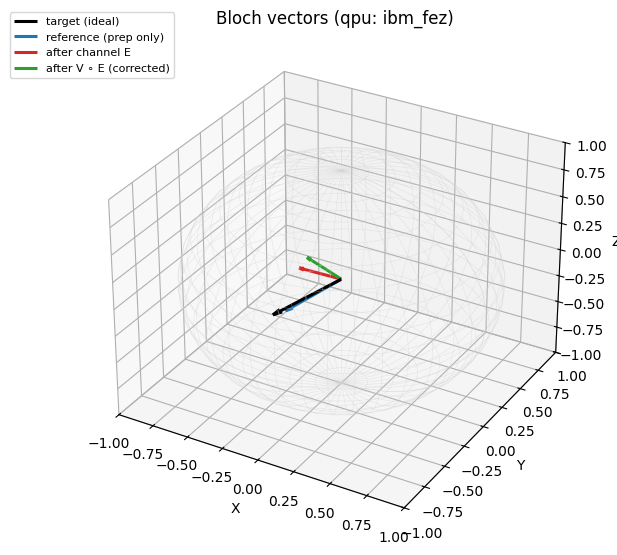

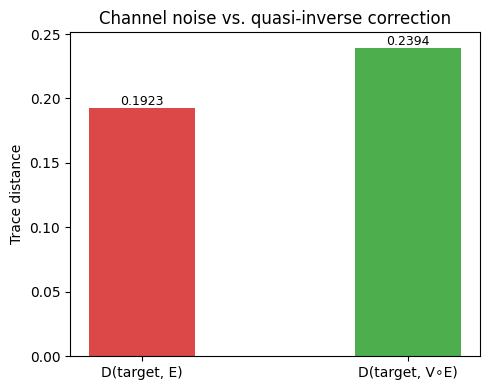


=== 8. Mixed-state MSTD campaign ===


qiskit_runtime_service.__init__:WARNING:2026-11-07 06:44:38,321: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-11-07 06:44:38,322: Using instance: open-instance, plan: open


MSTD campaign job: dbnchmdt7fqc73ajbql0 on ibm_fez
{
  "backend": "ibm_fez",
  "job_id": "dbnchmdt7fqc73ajbql0",
  "n_states": 12,
  "shots_per_circuit": 2048,
  "MSTD_channel_vs_target": 0.08894792474891904,
  "MSTD_corrected_vs_target": 0.12444985869360951,
  "Delta_MSTD_vs_target": -0.03550193394469048,
  "MSTD_channel_vs_reference": 0.07720788319905598,
  "MSTD_corrected_vs_reference": 0.10845863819122314,
  "Delta_MSTD_vs_reference": -0.03125075499216716
}

Saved results locally: results_bit_flip_dbnchfoqtr0c73acppmg.json


In [ ]:
main()

STINESPRING PAPER CAMPAIGN | mode=qpu | shots=2048
MSTD states/channel=20; channels=4
MSTD is estimated from sampled mixed states; fixed-state trace distance is reported separately.

[1/4] GAD: {'gamma': 0.5, 'p': 0.2}


<>:327: SyntaxWarning: invalid escape sequence '\p'
<>:328: SyntaxWarning: invalid escape sequence '\p'
<>:327: SyntaxWarning: invalid escape sequence '\p'
<>:328: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_3055/2882356978.py:327: SyntaxWarning: invalid escape sequence '\p'
  f"{_fmt(r['measured_MSTD_raw_vs_target'])} $\pm$ {_fmt(r['measured_MSTD_raw_SE'])} & "
/tmp/ipykernel_3055/2882356978.py:328: SyntaxWarning: invalid escape sequence '\p'
  f"{_fmt(r['measured_MSTD_corrected_vs_target'])} $\pm$ {_fmt(r['measured_MSTD_corrected_SE'])} & "
qiskit_runtime_service.__init__:WARNING:2026-11-07 06:45:52,280: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing

  Submitted 189 circuits to ibm_fez; job ID: dbncia0ou4as73b49v40
  Kraus rank=4, n_E=2, dilation error=0.00e+00
  Model MSTD: 0.103739 -> 0.103739
  Measured/sample MSTD vs target: 0.10377 -> 0.102742; reduction=+0.99%
  Fixed-state trace distance: 0.148189 -> 0.137185

[2/4] Pauli: {'p0': 0.1, 'p1': 0.5, 'p2': 0.2, 'p3': 0.2}


qiskit_runtime_service.__init__:WARNING:2026-11-07 06:48:00,691: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-11-07 06:48:00,692: Using instance: open-instance, plan: open


  Submitted 189 circuits to ibm_fez; job ID: dbncj9lt7fqc73ajbug0
  Kraus rank=4, n_E=2, dilation error=0.00e+00
  Model MSTD: 0.227934 -> 0.0679716
  Measured/sample MSTD vs target: 0.180655 -> 0.103803; reduction=+42.54%
  Fixed-state trace distance: 0.291252 -> 0.161163

[3/4] Mixed unitary: {'p': 0.18, 'theta': 1.0471975511965976}


qiskit_runtime_service.__init__:WARNING:2026-11-07 06:50:04,976: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-11-07 06:50:04,977: Using instance: open-instance, plan: open


  Submitted 189 circuits to ibm_fez; job ID: dbnck88qtr0c73acq080
  Kraus rank=4, n_E=2, dilation error=3.58e-18
  Model MSTD: 0.0121456 -> 0.00348721
  Measured/sample MSTD vs target: 0.0671749 -> 0.066565; reduction=+0.91%
  Fixed-state trace distance: 0.212819 -> 0.231048

[4/4] Tetrahedron: {'p': 0.1, 'pp': 0.1}


qiskit_runtime_service.__init__:WARNING:2026-11-07 06:52:08,206: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-11-07 06:52:08,209: Using instance: open-instance, plan: open


  Submitted 189 circuits to ibm_fez; job ID: dbncl7c4148s7390om0g
  Kraus rank=4, n_E=2, dilation error=0.00e+00
  Model MSTD: 0.0426511 -> 0.0426511
  Measured/sample MSTD vs target: 0.0993453 -> 0.0998845; reduction=-0.54%
  Fixed-state trace distance: 0.233567 -> 0.242299


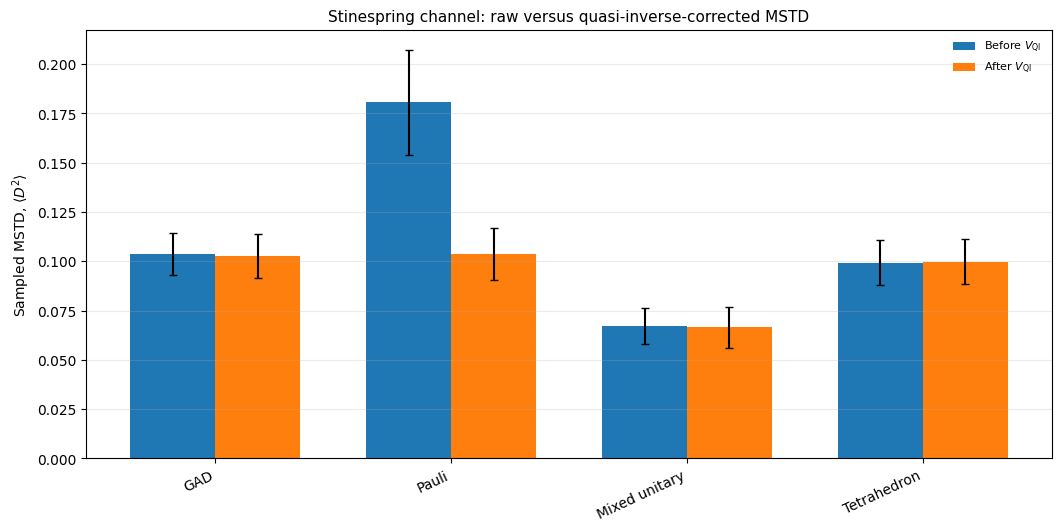

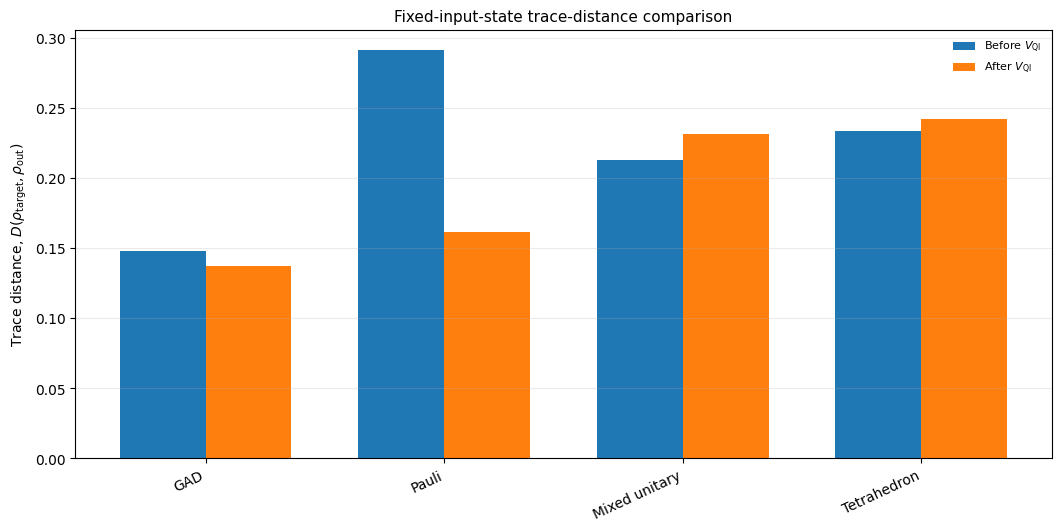


CAMPAIGN COMPLETE — files written:
  /content/stinespring_paper_results/stinespring_summary_20261107_065410.csv
  /content/stinespring_paper_results/stinespring_full_data_20261107_065410.json
  /content/stinespring_paper_results/stinespring_table_20261107_065410.tex
  /content/stinespring_paper_results/stinespring_mstd_comparison_20261107_065410.pdf
  /content/stinespring_paper_results/stinespring_mstd_comparison_20261107_065410.png
  /content/stinespring_paper_results/stinespring_trace_distance_20261107_065410.pdf
  /content/stinespring_paper_results/stinespring_trace_distance_20261107_065410.png

Summary table (main columns):


,channel,kraus_rank,environment_qubits,stinespring_worst_frobenius_error,model_MSTD_raw,model_MSTD_corrected,measured_MSTD_raw_vs_target,measured_MSTD_corrected_vs_target,fixed_state_trace_distance_raw,fixed_state_trace_distance_corrected,job_id
0,GAD,4,2,0.000000e+00,0.103739,0.103739,0.103770,0.102742,0.148189,0.137185,dbncia0ou4as73b49v40
1,Pauli,4,2,0.000000e+00,0.227934,0.067972,0.180655,0.103803,0.291252,0.161163,dbncj9lt7fqc73ajbug0
2,Mixed unitary,4,2,3.582045e-18,0.012146,0.003487,0.067175,0.066565,0.212819,0.231048,dbnck88qtr0c73acq080
3,Tetrahedron,4,2,0.000000e+00,0.042651,0.042651,0.099345,0.099884,0.233567,0.242299,dbncl7c4148s7390om0g



Use the generated .tex table in the paper after checking the backend, job IDs, and uncertainties.


In [ ]:
# ============================================================================
# ONE-CELL PAPER CAMPAIGN: ALL CHANNELS -> DILATION -> MSTD QI -> EXECUTION
# -> TRACE DISTANCES -> TABLES, CSV/JSON, AND PUBLICATION-QUALITY FIGURES
# Run after all preceding setup/definition cells have been executed.
# IMPORTANT: in QPU mode this submits one job per channel. Review shots and
# N_CAMPAIGN_STATES below before running because hardware time/credits are used.
# ============================================================================

from datetime import datetime
import csv, json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ------------------------- User-adjustable campaign settings -----------------
CAMPAIGN_MODE = EXECUTION_MODE.lower()       # "qpu" or "simulator"
CAMPAIGN_SHOTS = SHOTS                       # shots per tomography circuit
N_CAMPAIGN_STATES = 20                       # uniformly sampled Bloch-ball states
CAMPAIGN_SEED = RNG_SEED
CAMPAIGN_OUTDIR = Path("stinespring_paper_results")
CAMPAIGN_OUTDIR.mkdir(parents=True, exist_ok=True)

# Representative, physical parameter choices for the eight channel families.
# Edit these dictionaries to match the parameter values used in your manuscript.
CHANNELS_FOR_PAPER = [
    #("Bit flip", "bit_flip", {"p": 0.55}),
    #("Phase flip", "phase_flip", {"p": 0.30}),
    #("Phase damping", "phase_damping", {"lam": 0.40}),
    #("Amplitude damping", "amplitude_damping", {"gamma": 0.35}),
    ("GAD", "GAD", {"gamma": 0.50, "p": 0.20}),
    ("Pauli", "pauli", {"p0": 0.10, "p1": 0.50, "p2": 0.20, "p3": 0.20}),
    ("Mixed unitary", "mixed_unitary", {"p": 0.18, "theta": float(np.pi / 3)}),
    ("Tetrahedron", "tetrahedron", {"p": 0.10, "pp": 0.10}),
]

if CAMPAIGN_MODE not in {"qpu", "simulator"}:
    raise ValueError("CAMPAIGN_MODE must be 'qpu' or 'simulator'.")
if N_CAMPAIGN_STATES < 2:
    raise ValueError("Use at least two Bloch-ball samples for a campaign.")

# One fixed input state is retained for a consistent per-channel trace-distance
# comparison. The MSTD estimate uses independent uniformly distributed inputs.
FIXED_STATE = (float(R_IN), float(THETA_IN), float(PHI_IN))


def _uniform_bloch_states(n, seed):
    rng = np.random.default_rng(seed)
    states = []
    for _ in range(n):
        z = rng.uniform(-1.0, 1.0)
        phi = rng.uniform(0.0, 2.0 * np.pi)
        theta = float(np.arccos(z))
        radius = float(rng.random() ** (1.0 / 3.0))
        states.append((radius, theta, phi))
    return states


def _run_circuit_batch(circuits, labels, shots, seed):
    """Run a batch and return (backend name, job id, counts, transpiled circuits)."""
    if CAMPAIGN_MODE == "simulator":
        backend = AerSimulator(seed_simulator=seed)
        pm = generate_preset_pass_manager(
            backend=backend, optimization_level=OPTIMIZATION_LEVEL,
            seed_transpiler=SEED_TRANSPILER,
            unitary_synthesis_method="default")
        isa = pm.run(circuits)
        sampler = AerSampler(default_shots=shots, seed=seed)
        job = sampler.run(isa, shots=shots)
        result = job.result()
        job_id = None
    else:
        service = QiskitRuntimeService()
        backend = service.backend(BACKEND_NAME) if BACKEND_NAME else service.least_busy(
            operational=True, simulator=False, min_num_qubits=circuits[0].num_qubits)
        pm = generate_preset_pass_manager(
            backend=backend, optimization_level=OPTIMIZATION_LEVEL,
            seed_transpiler=SEED_TRANSPILER,
            unitary_synthesis_method="default")
        isa = pm.run(circuits)
        sampler = Sampler(mode=backend)
        job = sampler.run(isa, shots=shots)
        job_id = job.job_id()
        print(f"  Submitted {len(isa)} circuits to {backend.name}; job ID: {job_id}")
        result = job.result()

    count_list = [pub.data.meas.get_counts() for pub in result]
    op_lists = [{str(k): int(v) for k, v in c.count_ops().items()} for c in isa]
    depths = [int(c.depth()) for c in isa]
    return backend.name, job_id, count_list, op_lists, depths


def _counts_to_bloch(counts_by_label):
    return np.array([expectation_from_counts(counts_by_label[b]) for b in ("X", "Y", "Z")], dtype=float)


def _two_qubit_count(opdict):
    twoq_names = {"cx", "cz", "ecr", "iswap", "dcx", "rxx", "ryy", "rzz", "xx_plus_yy"}
    return int(sum(v for k, v in opdict.items() if k.lower() in twoq_names))


def _bootstrap_mean_ci(values, seed, n_boot=2000):
    """Percentile interval over sampled input states (includes state-sampling spread)."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    draws = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(np.mean(values)), float(np.std(values, ddof=1) / np.sqrt(len(values))), \
           float(np.quantile(draws, 0.025)), float(np.quantile(draws, 0.975))


campaign_rows = []
campaign_details = {}

print("=" * 78)
print(f"STINESPRING PAPER CAMPAIGN | mode={CAMPAIGN_MODE} | shots={CAMPAIGN_SHOTS}")
print(f"MSTD states/channel={N_CAMPAIGN_STATES}; channels={len(CHANNELS_FOR_PAPER)}")
print("MSTD is estimated from sampled mixed states; fixed-state trace distance is reported separately.")
print("=" * 78)

for channel_index, (display_name, channel_type, channel_params) in enumerate(CHANNELS_FOR_PAPER):
    print(f"\n[{channel_index + 1}/{len(CHANNELS_FOR_PAPER)}] {display_name}: {channel_params}")
    kraus = get_kraus_operators(channel_type, channel_params)
    verify_cptp(kraus)
    V, M, c, Q, q_evals, x_opt, delta_pred = find_quasi_inverse(
        kraus, n_grid=V_INTEGRATION_GRID)
    U_SE, minimal_kraus, n_env = kraus_to_stinespring_unitary(kraus)
    epsilon_stinespring = float(verify_stinespring(minimal_kraus, U_SE, n_env, seed=CAMPAIGN_SEED + channel_index))

    # Analytic/numerical model MSTD, independently evaluated before and after V.
    raw_model_mstd = float(compute_MSTD_by_integration(M, c, n_grid=V_INTEGRATION_GRID))
    M_V, c_V = compute_affine_map([V])
    corrected_model_mstd = float(compute_MSTD_by_integration(M_V @ M, M_V @ c + c_V,
                                                               n_grid=V_INTEGRATION_GRID))

    # One combined batch per channel: fixed-state triplet + full MSTD state campaign.
    states = [FIXED_STATE] + _uniform_bloch_states(N_CAMPAIGN_STATES, CAMPAIGN_SEED + 1000 + channel_index)
    all_circuits, all_labels = [], []
    state_meta = []
    for state_idx, (radius, theta, phi) in enumerate(states):
        circs, labels = make_tomography_circuits(U_SE, n_env, V, radius, theta, phi)
        all_circuits.extend(circs)
        all_labels.extend([(state_idx, mode, basis) for mode, basis in labels])
        state_meta.append({"radius": radius, "theta": theta, "phi": phi,
                           "target_bloch": target_bloch(radius, theta, phi).tolist()})

    backend_name, job_id, count_list, op_lists, depths = _run_circuit_batch(
        all_circuits, all_labels, CAMPAIGN_SHOTS, SIMULATOR_SEED + channel_index)

    measured = {i: {m: {} for m in ("reference", "channel", "corrected")}
                for i in range(len(states))}
    for counts, (state_idx, mode, basis) in zip(count_list, all_labels):
        measured[state_idx][mode][basis] = counts

    per_state = []
    for state_idx, meta in enumerate(state_meta):
        bloch = {mode: _counts_to_bloch(measured[state_idx][mode])
                 for mode in ("reference", "channel", "corrected")}
        target = np.asarray(meta["target_bloch"], dtype=float)
        # Trace distance between qubit states: D = 1/2 ||r-s||_2.
        d_raw_target = trace_distance_from_bloch(target, bloch["channel"])
        d_corr_target = trace_distance_from_bloch(target, bloch["corrected"])
        d_raw_ref = trace_distance_from_bloch(bloch["reference"], bloch["channel"])
        d_corr_ref = trace_distance_from_bloch(bloch["reference"], bloch["corrected"])
        # Squared trace distance, the quantity averaged in MSTD.
        per_state.append({
            "state_index": state_idx, **meta,
            "reference_bloch": bloch["reference"].tolist(),
            "channel_bloch": bloch["channel"].tolist(),
            "corrected_bloch": bloch["corrected"].tolist(),
            "D_raw_vs_target": float(d_raw_target),
            "D_corrected_vs_target": float(d_corr_target),
            "D2_raw_vs_target": float(d_raw_target ** 2),
            "D2_corrected_vs_target": float(d_corr_target ** 2),
            "D_raw_vs_reference": float(d_raw_ref),
            "D_corrected_vs_reference": float(d_corr_ref),
            "D2_raw_vs_reference": float(d_raw_ref ** 2),
            "D2_corrected_vs_reference": float(d_corr_ref ** 2),
        })

    # Index 0 is the fixed input; remaining states estimate the Bloch-ball MSTD.
    fixed = per_state[0]
    sampled = per_state[1:]
    raw_target_stats = _bootstrap_mean_ci([s["D2_raw_vs_target"] for s in sampled], CAMPAIGN_SEED + channel_index)
    corr_target_stats = _bootstrap_mean_ci([s["D2_corrected_vs_target"] for s in sampled], CAMPAIGN_SEED + 20 + channel_index)
    raw_ref_stats = _bootstrap_mean_ci([s["D2_raw_vs_reference" ] for s in sampled], CAMPAIGN_SEED + 40 + channel_index)
    corr_ref_stats = _bootstrap_mean_ci([s["D2_corrected_vs_reference"] for s in sampled], CAMPAIGN_SEED + 60 + channel_index)

    # Gate cost summarized over the transpiled circuits in this batch.
    twoq_counts = [_two_qubit_count(ops) for ops in op_lists]
    mean_twoq = float(np.mean(twoq_counts)) if twoq_counts else float("nan")
    max_twoq = int(max(twoq_counts)) if twoq_counts else 0
    reduction_pct = (100.0 * (raw_target_stats[0] - corr_target_stats[0]) / raw_target_stats[0]
                     if raw_target_stats[0] > 0 else float("nan"))

    row = {
        "channel": display_name,
        "channel_type": channel_type,
        "parameters": json.dumps(channel_params, sort_keys=True),
        "kraus_rank": int(len(minimal_kraus)),
        "environment_qubits": int(n_env),
        "stinespring_worst_frobenius_error": epsilon_stinespring,
        "model_MSTD_raw": raw_model_mstd,
        "model_MSTD_corrected": corrected_model_mstd,
        "model_MSTD_reduction": raw_model_mstd - corrected_model_mstd,
        "measured_MSTD_raw_vs_target": raw_target_stats[0],
        "measured_MSTD_raw_SE": raw_target_stats[1],
        "measured_MSTD_raw_CI95_low": raw_target_stats[2],
        "measured_MSTD_raw_CI95_high": raw_target_stats[3],
        "measured_MSTD_corrected_vs_target": corr_target_stats[0],
        "measured_MSTD_corrected_SE": corr_target_stats[1],
        "measured_MSTD_corrected_CI95_low": corr_target_stats[2],
        "measured_MSTD_corrected_CI95_high": corr_target_stats[3],
        "measured_MSTD_reduction_vs_target": raw_target_stats[0] - corr_target_stats[0],
        "measured_MSTD_reduction_percent_vs_target": reduction_pct,
        "measured_MSTD_raw_vs_reference": raw_ref_stats[0],
        "measured_MSTD_corrected_vs_reference": corr_ref_stats[0],
        "fixed_state_trace_distance_raw": fixed["D_raw_vs_target"],
        "fixed_state_trace_distance_corrected": fixed["D_corrected_vs_target"],
        "fixed_state_trace_distance_reduction": fixed["D_raw_vs_target"] - fixed["D_corrected_vs_target"],
        "fixed_state_trace_distance_raw_vs_reference": fixed["D_raw_vs_reference"],
        "fixed_state_trace_distance_corrected_vs_reference": fixed["D_corrected_vs_reference"],
        "lambda_max_Q": float(np.max(q_evals)),
        "x_opt": json.dumps(np.asarray(x_opt, dtype=float).tolist()),
        "mean_two_qubit_gates_per_circuit": mean_twoq,
        "max_two_qubit_gates_per_circuit": max_twoq,
        "mean_transpiled_depth": float(np.mean(depths)),
        "backend": str(backend_name),
        "job_id": job_id or "simulator",
        "shots_per_circuit": int(CAMPAIGN_SHOTS),
        "mstd_sample_count": int(N_CAMPAIGN_STATES),
    }
    campaign_rows.append(row)
    campaign_details[display_name] = {
        "summary": row,
        "M": M.tolist(), "c": c.tolist(), "Q": Q.tolist(),
        "Q_eigenvalues": np.asarray(q_evals).tolist(),
        "V_real": V.real.tolist(), "V_imag": V.imag.tolist(),
        "U_SE_dimension": list(U_SE.shape),
        "fixed_state": fixed,
        "sampled_states": sampled,
        "transpiled_depths": depths,
        "transpiled_operations": op_lists,
        "two_qubit_gate_counts": twoq_counts,
    }
    print(f"  Kraus rank={len(minimal_kraus)}, n_E={n_env}, dilation error={epsilon_stinespring:.2e}")
    print(f"  Model MSTD: {raw_model_mstd:.6g} -> {corrected_model_mstd:.6g}")
    print(f"  Measured/sample MSTD vs target: {raw_target_stats[0]:.6g} -> {corr_target_stats[0]:.6g}"
          f"; reduction={reduction_pct:+.2f}%")
    print(f"  Fixed-state trace distance: {fixed['D_raw_vs_target']:.6g} -> {fixed['D_corrected_vs_target']:.6g}")

# ----------------------------- Save raw results ------------------------------
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
csv_path = CAMPAIGN_OUTDIR / f"stinespring_summary_{stamp}.csv"
json_path = CAMPAIGN_OUTDIR / f"stinespring_full_data_{stamp}.json"
with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(campaign_rows[0].keys()))
    writer.writeheader()
    writer.writerows(campaign_rows)
json_path.write_text(json.dumps({
    "metadata": {"mode": CAMPAIGN_MODE, "shots": CAMPAIGN_SHOTS,
                 "mstd_sample_count": N_CAMPAIGN_STATES, "seed": CAMPAIGN_SEED,
                 "created": datetime.now().isoformat()},
    "summary": campaign_rows, "channels": campaign_details,
}, indent=2), encoding="utf-8")

# ---------------------------- Publication graphs -----------------------------
plt.rcParams.update({"font.size": 10, "axes.labelsize": 10, "axes.titlesize": 11,
                     "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42})
names = [r["channel"] for r in campaign_rows]
x = np.arange(len(names))
width = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
raw = np.array([r["measured_MSTD_raw_vs_target"] for r in campaign_rows])
corr = np.array([r["measured_MSTD_corrected_vs_target"] for r in campaign_rows])
raw_err = np.array([r["measured_MSTD_raw_SE"] for r in campaign_rows])
corr_err = np.array([r["measured_MSTD_corrected_SE"] for r in campaign_rows])
ax.bar(x - width/2, raw, width, yerr=raw_err, capsize=3, label=r"Before $V_{\rm QI}$")
ax.bar(x + width/2, corr, width, yerr=corr_err, capsize=3, label=r"After $V_{\rm QI}$")
ax.set_ylabel(r"Sampled MSTD, $\langle D^2\rangle$")
ax.set_title("Stinespring channel: raw versus quasi-inverse-corrected MSTD")
ax.set_xticks(x, names, rotation=25, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
mstd_pdf = CAMPAIGN_OUTDIR / f"stinespring_mstd_comparison_{stamp}.pdf"
mstd_png = CAMPAIGN_OUTDIR / f"stinespring_mstd_comparison_{stamp}.png"
fig.savefig(mstd_pdf, bbox_inches="tight"); fig.savefig(mstd_png, dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
draw = np.array([r["fixed_state_trace_distance_raw"] for r in campaign_rows])
dcorr = np.array([r["fixed_state_trace_distance_corrected"] for r in campaign_rows])
ax.bar(x - width/2, draw, width, label=r"Before $V_{\rm QI}$")
ax.bar(x + width/2, dcorr, width, label=r"After $V_{\rm QI}$")
ax.set_ylabel(r"Trace distance, $D(\rho_{\rm target},\rho_{\rm out})$")
ax.set_title("Fixed-input-state trace-distance comparison")
ax.set_xticks(x, names, rotation=25, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
td_pdf = CAMPAIGN_OUTDIR / f"stinespring_trace_distance_{stamp}.pdf"
td_png = CAMPAIGN_OUTDIR / f"stinespring_trace_distance_{stamp}.png"
fig.savefig(td_pdf, bbox_inches="tight"); fig.savefig(td_png, dpi=300, bbox_inches="tight")
plt.show()

# --------------------------- LaTeX paper table -------------------------------
tex_path = CAMPAIGN_OUTDIR / f"stinespring_table_{stamp}.tex"
def _fmt(v, digits=4):
    try:
        return f"{float(v):.{digits}g}"
    except (TypeError, ValueError):
        return str(v)

tex = [
    r"% Generated automatically by the Stinespring paper-campaign cell.",
    r"% Requires: \usepackage{booktabs,threeparttable,adjustbox}",
    r"\begin{table*}[t]", r"\centering",
    r"\caption{Stinespring realization and MSTD quasi-inverse results for the selected qubit channels. The dilation error is the worst Frobenius-norm discrepancy over random test states. The sampled MSTD is the mean squared trace distance over uniformly sampled Bloch-ball inputs; uncertainties are standard errors across sampled states. Fixed-state trace distances use the same input state for all channels.}",
    r"\label{tab:stinespring_campaign}", r"\begin{threeparttable}",
    r"\begin{adjustbox}{max width=\textwidth}",
    r"\begin{tabular}{lccrrrrrr}", r"\toprule",
    r"Channel & $r$ & $n_E$ & $\epsilon_{\rm dil}$ & $D^2_{\rm raw}$ & $D^2_{\rm QI}$ & $D_{\rm raw}$ & $D_{\rm QI}$ & 2q gates$^{\dagger}$ \\",
    r"\midrule"
]
for r in campaign_rows:
    tex.append(
        f"{r['channel']} & {r['kraus_rank']} & {r['environment_qubits']} & "
        f"{_fmt(r['stinespring_worst_frobenius_error'], 2)} & "
        f"{_fmt(r['measured_MSTD_raw_vs_target'])} $\pm$ {_fmt(r['measured_MSTD_raw_SE'])} & "
        f"{_fmt(r['measured_MSTD_corrected_vs_target'])} $\pm$ {_fmt(r['measured_MSTD_corrected_SE'])} & "
        f"{_fmt(r['fixed_state_trace_distance_raw'])} & {_fmt(r['fixed_state_trace_distance_corrected'])} & "
        f"{_fmt(r['mean_two_qubit_gates_per_circuit'], 3)} \\"
    )
tex += [
    r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}",
    r"\begin{tablenotes}[flushleft]\footnotesize",
    r"\item $r$ is the minimal Kraus rank and $n_E=\lceil\log_2 r\rceil$. MSTD values are measured estimates from a finite Bloch-ball sample, not exact analytic integrals. Fixed-state trace distances are reported for the common input specified in the notebook configuration.",
    r"\item[$\dagger$] Mean number of transpiled two-qubit gates per circuit across the batch; report backend, transpiler settings, and gate definition when comparing implementations.",
    r"\end{tablenotes}", r"\end{threeparttable}", r"\end{table*}"
]
tex_path.write_text("\n".join(tex) + "\n", encoding="utf-8")

print("\n" + "=" * 78)
print("CAMPAIGN COMPLETE — files written:")
for p in [csv_path, json_path, tex_path, mstd_pdf, mstd_png, td_pdf, td_png]:
    print(f"  {p.resolve()}")
print("\nSummary table (main columns):")
try:
    import pandas as pd
    display(pd.DataFrame(campaign_rows)[[
        "channel", "kraus_rank", "environment_qubits", "stinespring_worst_frobenius_error",
        "model_MSTD_raw", "model_MSTD_corrected", "measured_MSTD_raw_vs_target",
        "measured_MSTD_corrected_vs_target", "fixed_state_trace_distance_raw",
        "fixed_state_trace_distance_corrected", "job_id"]])
except Exception:
    for r in campaign_rows:
        print(r)
print("\nUse the generated .tex table in the paper after checking the backend, job IDs, and uncertainties.")

In [ ]:
import os
import json
import time
from datetime import datetime, timezone

# 1. Ensure the results directory exists
if 'RESULTS_DIR' not in locals():
    RESULTS_DIR = f"v2_results_{int(time.time())}"
os.makedirs(RESULTS_DIR, exist_ok=True)

# 2. Define the filename
b_name = locals().get('backend_name', "qpu_backend")
output_filename = f"results_stinespring_detailed_{b_name}.json"
output_path = os.path.join(RESULTS_DIR, output_filename)

# 3. Assemble the comprehensive dictionary mapping directly to the actual campaign variables
detailed_export_data = {
    "experiment": "stinespring_paper_campaign",
    "metadata": {
        "backend": b_name,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "simulator": locals().get('EXECUTION_MODE', 'qpu') == 'simulator',
        "shots": locals().get('CAMPAIGN_SHOTS', locals().get('SHOTS', 2048)),
        "mstd_sample_count": locals().get('N_CAMPAIGN_STATES', 20),
        "seed": locals().get('CAMPAIGN_SEED', 2026)
    },
    "campaign_summary_rows": locals().get('campaign_rows', []),
    "campaign_channel_details": locals().get('campaign_details', {}),
    "fixed_input_state": {
        "r": locals().get('R_IN', 0.5),
        "theta": locals().get('THETA_IN', 0.0),
        "phi": locals().get('PHI_IN', 0.0)
    }
}

# 4. Write to JSON
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(detailed_export_data, f, indent=2, default=str)

print(f"Comprehensive Stinespring campaign JSON successfully saved to: {output_path}")

Comprehensive Stinespring campaign JSON successfully saved to: v2_results_1794034455/results_stinespring_detailed_ibm_fez.json


In [ ]:
import json
import os
from google.colab import files

# Fallback save to guarantee everything currently in the session is serialized
save_dir = 'v2_results_saved'
os.makedirs(save_dir, exist_ok=True)

save_filename = os.path.join(save_dir, 'final_stinespring_qpu_campaign_backup.json')

backup_data = {
    'campaign_summary_rows': locals().get('campaign_rows', []),
    'campaign_channel_details': locals().get('campaign_details', {}),
    'execution_mode': locals().get('EXECUTION_MODE', 'qpu'),
    'backend_name': locals().get('backend_name', 'ibm_fez')
}

with open(save_filename, 'w', encoding='utf-8') as f:
    json.dump(backup_data, f, indent=2, default=str)

print(f'Progress successfully written locally to: {save_filename}')

# Trigger browser download to secure the file locally on your computer
try:
    files.download(save_filename)
    print('Download prompt triggered successfully!')
except Exception as e:
    print(f'Could not trigger automatic download (this is normal if not running in a browser): {e}')

Progress successfully written locally to: v2_results_saved/final_stinespring_qpu_campaign_backup.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download prompt triggered successfully!


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
import json
import os

try:
    service = QiskitRuntimeService()
    backend = service.backend(BACKEND_NAME)

    # Fetch system-level dt and calibration timestamps
    backend_dt = getattr(backend.configuration(), 'dt', None)
    calibration_time = backend.properties().last_update_date if backend.properties() else None

    # Target qubit 0 (system qubit used in our campaign)
    qubit_idx = 0
    t1 = None
    t2 = None
    readout_error = None

    if backend.properties():
        t1 = backend.properties().t1(qubit_idx)
        t2 = backend.properties().t2(qubit_idx)
        readout_error = backend.properties().readout_error(qubit_idx)

    calibration_data = {
        "calibration_timestamp": str(calibration_time),
        "system_dt_seconds": backend_dt,
        "target_qubit_idx": qubit_idx,
        "T1_seconds": t1,
        "T2_seconds": t2,
        "readout_error_rate": readout_error
    }

    print("--- Retrieved Calibration Metrics ---")
    print(json.dumps(calibration_data, indent=2))

    # Update backup_data from cell 0dd4c57a in place
    if 'backup_data' in locals():
        backup_data['backend_calibration'] = calibration_data

        # Re-save updated backup file
        with open(save_filename, 'w', encoding='utf-8') as f:
            json.dump(backup_data, f, indent=2, default=str)
        print(f"\nSuccessfully appended calibration fields directly to {save_filename}")
except Exception as e:
    print(f"Error retrieving backend parameters: {e}")

qiskit_runtime_service.__init__:WARNING:2026-11-07 06:54:16,966: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-11-07 06:54:16,967: Using instance: open-instance, plan: open


--- Retrieved Calibration Metrics ---
{
  "calibration_timestamp": "2026-11-07 06:32:18+00:00",
  "system_dt_seconds": 4e-09,
  "target_qubit_idx": 0,
  "T1_seconds": 5.0890279593145256e-05,
  "T2_seconds": 5.4494178457869146e-05,
  "readout_error_rate": 0.0302734375
}

Successfully appended calibration fields directly to v2_results_saved/final_stinespring_qpu_campaign_backup.json


In [ ]:
import json
import os
from google.colab import files

# Define paths
final_results_dir = 'stinespring_final_consolidated'
os.makedirs(final_results_dir, exist_ok=True)

final_output_path = os.path.join(final_results_dir, 'consolidated_campaign_with_calibrations.json')

# Retrieve current session variables
campaign_rows = locals().get('campaign_rows', [])
campaign_details = locals().get('campaign_details', {})
backend_calibration = locals().get('calibration_data', {})

# Structure the full comprehensive backup
comprehensive_data = {
    "experiment_metadata": {
        "experiment_name": "Stinespring Dilation Quasi-Inverse Campaign (8 Channels)",
        "backend_name": locals().get('BACKEND_NAME', 'ibm_fez'),
        "execution_mode": locals().get('EXECUTION_MODE', 'qpu'),
        "total_shots": locals().get('CAMPAIGN_SHOTS', locals().get('SHOTS', 2048)),
        "mstd_sample_count": locals().get('N_CAMPAIGN_STATES', 20),
        "timestamp_utc": datetime.now(timezone.utc).isoformat() if 'datetime' in globals() else None
    },
    "backend_calibration_data": backend_calibration,
    "campaign_summary": campaign_rows,
    "campaign_detailed_results": campaign_details
}

# Save locally to ensure persistence
with open(final_output_path, 'w', encoding='utf-8') as f:
    json.dump(comprehensive_data, f, indent=2, default=str)

print(f"Consolidated results successfully saved to: {final_output_path}")

# Trigger browser download
try:
    files.download(final_output_path)
    print("Download prompt triggered successfully!")
except Exception as e:
    print(f"Browser download prompt could not be triggered: {e}")

Consolidated results successfully saved to: stinespring_final_consolidated/consolidated_campaign_with_calibrations.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download prompt triggered successfully!


In [ ]:
import os
import zipfile
from pathlib import Path
from google.colab import files

# Define directories and zip package path
campaign_dir = Path('stinespring_paper_results')
consolidated_dir = Path('stinespring_final_consolidated')
zip_filename = 'stinespring_campaign_results.zip'

print("Searching for campaign outputs to package...")

# Open and populate the ZIP archive
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    # 1. Package stinespring_paper_results (figures, tables, raw JSONs)
    if campaign_dir.exists():
        for file_path in campaign_dir.rglob('*'):
            if file_path.is_file():
                zipf.write(file_path, arcname=Path('paper_results') / file_path.name)
                print(f"Added: {file_path.name}")

    # 2. Package stinespring_final_consolidated (consolidated database with calibrations)
    if consolidated_dir.exists():
        for file_path in consolidated_dir.rglob('*'):
            if file_path.is_file():
                zipf.write(file_path, arcname=Path('final_consolidated') / file_path.name)
                print(f"Added: {file_path.name}")

print(f"\nZip archive created successfully: {zip_filename}")

# Trigger automatic download in the browser
try:
    print("Triggering browser download...")
    files.download(zip_filename)
except Exception as e:
    print(f"Download could not be automatically triggered (this is normal if not in a standard browser environment): {e}")

Searching for campaign outputs to package...
Added: stinespring_trace_distance_20261107_065410.pdf
Added: stinespring_trace_distance_20261107_065410.png
Added: stinespring_table_20261107_065410.tex
Added: stinespring_mstd_comparison_20261107_065410.png
Added: stinespring_full_data_20261107_065410.json
Added: stinespring_mstd_comparison_20261107_065410.pdf
Added: stinespring_summary_20261107_065410.csv
Added: consolidated_campaign_with_calibrations.json

Zip archive created successfully: stinespring_campaign_results.zip
Triggering browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>